# EDA: анализ оттока клиентов телеком-компании

## Цель проекта

Исследовать факторы, связанные с оттоком клиентов, определить группы с повышенной долей оттока и сформулировать гипотезы для последующего построения модели прогнозирования.

## Бизнес-вопрос

Какие характеристики клиентов связаны с более высокой вероятностью оттока и какие клиентские сегменты требуют дополнительного исследования с точки зрения удержания?

## Этапы анализа

1. Проверка качества и структуры данных.
2. Исследование распределения целевой переменной.
3. Анализ числовых и категориальных признаков.
4. Сравнение оттока между клиентскими сегментами.
5. Проверка отдельных статистических гипотез.
6. Формулирование выводов, ограничений и следующих шагов для ML.

## Инструменты

Python, Pandas, NumPy, Matplotlib, Seaborn, SQLite.

## Описание данных

Источник: SQLite-база 'data/processed/churn.db', таблица 'customers'.

Единица наблюдения - клиент телеком-компании.

В таблице представлены сведения о стаже клиента, платежах, типе договора, подключённых услугах и других характеристиках.

Целевая переменная - 'Churn':

- 'Yes' - клиент прекратил обслуживание;
- 'No' - клиент остался.

Перед анализом проверяются структура таблицы, типы данных, пропуски, дубликаты и корректность значений.

In [1]:
%matplotlib inline
import sqlite3
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

RANDOM_STATE = 42

## Загрузка данных

In [2]:
DB_PATH = Path("../data/processed/churn.db")
FIGURES_DIR = Path("../reports/figures")

if not DB_PATH.exists():
    raise FileNotFoundError(
        f"База данных не найдена: {DB_PATH.resolve()}. "
        "Проверь рабочую директорию и путь к файлу."
    )

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

with sqlite3.connect(DB_PATH) as conn:
    df = pd.read_sql_query(
        "SELECT * FROM customers",
        conn
    )

print(f"Количество строк: {df.shape[0]}")
print(f"Количество столбцов: {df.shape[1]}")
display(df.head())

Количество строк: 7032
Количество столбцов: 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,"1,889.50",No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,"1,840.75",No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.info()

missing = df.isna().sum()
print("Столбцы с пропусками:")
display(missing[missing > 0])

print("Полных дубликатов:", df.duplicated().sum())
print(
    "Повторяющихся customerID:",
    df["customerID"].duplicated().sum()
)

display(df.describe().T)

for col in df.select_dtypes(include="object").columns:
    print(f"\n{col}: {df[col].nunique()} уникальных значений")
    display(df[col].value_counts(dropna=False).head(10))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7032 entries, 0 to 7031
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7032 non-null   object 
 1   gender            7032 non-null   object 
 2   SeniorCitizen     7032 non-null   int64  
 3   Partner           7032 non-null   object 
 4   Dependents        7032 non-null   object 
 5   tenure            7032 non-null   int64  
 6   PhoneService      7032 non-null   object 
 7   MultipleLines     7032 non-null   object 
 8   InternetService   7032 non-null   object 
 9   OnlineSecurity    7032 non-null   object 
 10  OnlineBackup      7032 non-null   object 
 11  DeviceProtection  7032 non-null   object 
 12  TechSupport       7032 non-null   object 
 13  StreamingTV       7032 non-null   object 
 14  StreamingMovies   7032 non-null   object 
 15  Contract          7032 non-null   object 
 16  PaperlessBilling  7032 non-null   object 


Series([], dtype: int64)

Полных дубликатов: 0
Повторяющихся customerID: 0


,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,"7,032.00",0.16,0.37,0.00,0.00,0.00,0.00,1.00
tenure,"7,032.00",32.42,24.55,1.00,9.00,29.00,55.00,72.00
MonthlyCharges,"7,032.00",64.80,30.09,18.25,35.59,70.35,89.86,118.75
TotalCharges,"7,032.00","2,283.30","2,266.77",18.80,401.45,"1,397.47","3,794.74","8,684.80"



customerID: 7032 уникальных значений


...

PaperlessBilling
Yes    4168
No     2864
Name: count, dtype: int64


PaymentMethod: 4 уникальных значений


PaymentMethod
Electronic check             2365
Mailed check                 1604
Bank transfer (automatic)    1542
Credit card (automatic)      1521
Name: count, dtype: int64


Churn: 2 уникальных значений


Churn
No     5163
Yes    1869
Name: count, dtype: int64

In [4]:
expected_categories = {
    "Churn": {"Yes", "No"},
    "Contract": {
        "Month-to-month",
        "One year",
        "Two year"
    },
    "PaperlessBilling": {"Yes", "No"},
    "InternetService": {
        "DSL",
        "Fiber optic",
        "No"
    }
}

for column, expected_values in expected_categories.items():
    actual_values = set(df[column].dropna().unique())

    unexpected_values = actual_values - expected_values

    print(f"\nСтолбец: {column}")
    print("Фактические значения:", actual_values)
    print("Неожиданные значения:", unexpected_values)

print("\nПроверка диапазонов:")

print(
    "tenure вне диапазона 0–72:",
    (~df["tenure"].between(0, 72)).sum()
)

print(
    "MonthlyCharges <= 0:",
    (df["MonthlyCharges"] <= 0).sum()
)

print(
    "TotalCharges < 0:",
    (df["TotalCharges"] < 0).sum()
)


Столбец: Churn
Фактические значения: {'No', 'Yes'}
Неожиданные значения: set()

Столбец: Contract
Фактические значения: {'One year', 'Month-to-month', 'Two year'}
Неожиданные значения: set()

Столбец: PaperlessBilling
Фактические значения: {'No', 'Yes'}
Неожиданные значения: set()

Столбец: InternetService
Фактические значения: {'No', 'Fiber optic', 'DSL'}
Неожиданные значения: set()

Проверка диапазонов:
tenure вне диапазона 0–72: 0
MonthlyCharges <= 0: 0
TotalCharges < 0: 0


Дополнительно проверены допустимые значения категориальных признаков и диапазоны числовых полей.

В проверенных столбцах неожиданных категорий, отрицательных суммарных платежей и значений вне установленных диапазонов не обнаружено.

## Результаты проверки качества данных

После загрузки таблица содержит 7 032 записи о клиентах и 21 столбец.

В загруженных данных пропуски не обнаружены. Типы данных соответствуют основным задачам анализа: числовые признаки представлены числовыми типами, категориальные — строковыми.

Проверены полные дубликаты строк и уникальность идентификатора `customerID`. Полных дубликатов не обнаружено, все значения customerID уникальны.
На этапе первичного анализа идентификатор `customerID` используется для идентификации клиента, но не рассматривается как содержательный признак для прогнозирования оттока.

,customers,share_pct
Churn,,
No,5163,73.42
Yes,1869,26.58


Доля ушедших клиентов: 26.58%


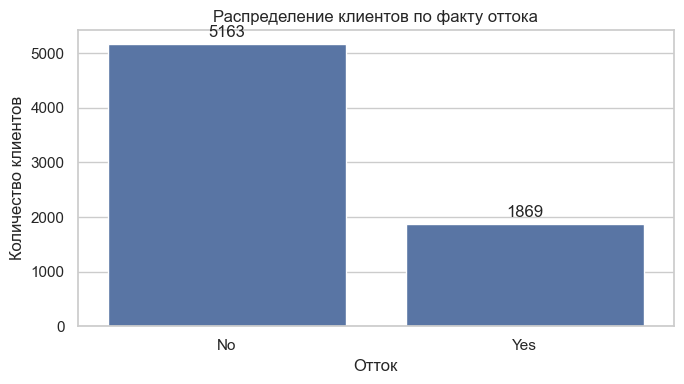

In [5]:
churn_counts = df["Churn"].value_counts()

churn_summary = pd.DataFrame({
    "customers": churn_counts,
    "share_pct": churn_counts / len(df) * 100
})
display(churn_summary.round(2))

churn_rate = (df["Churn"] == "Yes").mean() * 100
print(f"Доля ушедших клиентов: {churn_rate:.2f}%")

fig, ax = plt.subplots(figsize=(7, 4))
sns.countplot(
    data=df,
    x="Churn",
    order=["No", "Yes"],
    color="#4C72B0",
    ax=ax
)
ax.set_title("Распределение клиентов по факту оттока")
ax.set_xlabel("Отток")
ax.set_ylabel("Количество клиентов")

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)

plt.tight_layout()
fig.savefig(
    FIGURES_DIR / "churn_distribution.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

## Интерпретация целевой переменной

В выборке 1 869 ушедших клиентов из 7 032, что составляет 26,58%. Оставшиеся клиенты составляют 73,42%.

Таким образом, классы распределены неравномерно. При дальнейшем построении модели accuracy следует оценивать вместе с метриками, учитывающими качество обнаружения ушедших клиентов.

В качестве основных метрик для сравнения моделей можно рассмотреть precision, recall, F1-score и ROC-AUC. Выбор основной метрики зависит от цели прогнозирования и допустимого соотношения ложноположительных и ложноотрицательных прогнозов.

На этапе EDA не делается вывод о том, что использование `class_weight='balanced'` обязательно улучшит модель. Это вариант, который следует проверить экспериментально.

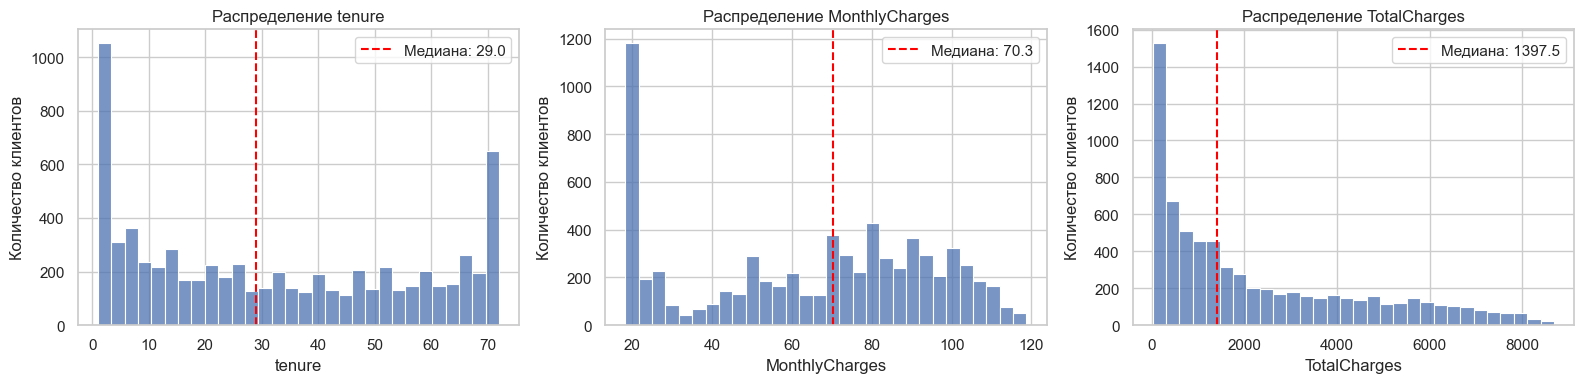

,mean,median,std,min,max,skewness
tenure,32.42,29.00,24.55,1.00,72.00,0.24
MonthlyCharges,64.80,70.35,30.09,18.25,118.75,-0.22
TotalCharges,"2,283.30","1,397.48","2,266.77",18.80,"8,684.80",0.96


In [6]:
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for col, ax in zip(num_cols, axes):
    sns.histplot(
        data=df,
        x=col,
        bins=30,
        kde=False,
        ax=ax
    )
    median_value = df[col].median()
    ax.axvline(
        median_value,
        linestyle="--",
        color="red",
        label=f"Медиана: {median_value:.1f}"
    )
    ax.set_title(f"Распределение {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Количество клиентов")
    ax.legend()

plt.tight_layout()
fig.savefig(
    FIGURES_DIR / "numeric_distributions.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

distribution_summary = df[num_cols].agg(
    ["mean", "median", "std", "min", "max"]
).T
distribution_summary["skewness"] = df[num_cols].skew()
display(distribution_summary.round(2))

## Интерпретация числовых распределений

- `tenure`: распределение неоднородное, наблюдаются скопления клиентов с небольшим и большим стажем. Необходимо отдельно проверить, как доля оттока меняется с увеличением стажа.
- `MonthlyCharges`: распределение неоднородное, с выраженным скоплением клиентов в нижней части диапазона и дополнительными скоплениями в более высоких диапазонах.
- `TotalCharges`: распределение с длинным правым хвостом. Суммарные платежи связаны со стажем обслуживания и размером ежемесячной платы.

Форма распределений важна для интерпретации данных, но сама по себе не определяет выбор модели. Масштабирование, преобразования и создание дополнительных признаков должны оцениваться с учётом используемого алгоритма и результатов валидации.

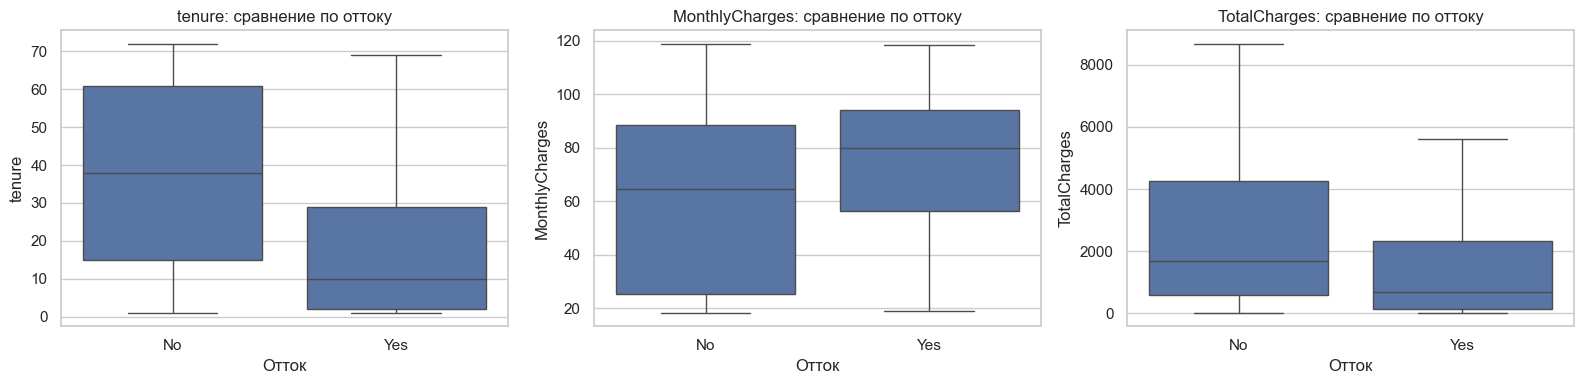

tenure                    MonthlyCharges                     \
       count median  mean   std          count median  mean   std   
Churn                                                               
No      5163  38.00 37.65 24.08           5163  64.45 61.31 31.09   
Yes     1869  10.00 17.98 19.53           1869  79.65 74.44 24.67   

      TotalCharges                             
             count   median     mean      std  
Churn                                          
No            5163 1,683.60 2,555.34 2,329.46  
Yes           1869   703.55 1,531.80 1,890.82

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for col, ax in zip(num_cols, axes):
    sns.boxplot(
        data=df,
        x="Churn",
        y=col,
        order=["No", "Yes"],
        showfliers=False,
        ax=ax
    )
    ax.set_title(f"{col}: сравнение по оттоку")
    ax.set_xlabel("Отток")
    ax.set_ylabel(col)

plt.tight_layout()
fig.savefig(
    FIGURES_DIR / "numeric_by_churn.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

numeric_by_churn = (
    df.groupby("Churn")[num_cols]
    .agg(["count", "median", "mean", "std"])
    .round(2)
)
display(numeric_by_churn)

## Сравнение числовых признаков по факту оттока

Для сравнения числовых характеристик клиентов использованы boxplot и групповые статистики по целевой переменной `Churn`.

**Стаж обслуживания (`tenure`).**

Медианный стаж клиентов, оставшихся с компанией, составляет 38 месяцев. У ушедших клиентов медиана равна 10 месяцам.

Таким образом, ушедшие клиенты в этой выборке в среднем имеют значительно меньший стаж обслуживания по сравнению с оставшимися клиентами.

Это наблюдение указывает на необходимость более подробного анализа оттока среди клиентов с небольшим стажем.

**Ежемесячная плата (`MonthlyCharges`).**

Медиана ежемесячной платы у оставшихся клиентов составляет 64,45, а у ушедших — 79,65.

Следовательно, среди ушедших клиентов наблюдается более высокая медианная ежемесячная плата.

Однако это различие не доказывает, что высокая стоимость услуг является причиной прекращения обслуживания. На размер платежа могут влиять тип подключения, набор услуг и другие характеристики клиента.

**Суммарные платежи (`TotalCharges`).**

Медиана суммарных платежей у оставшихся клиентов составляет 1 683,60, а у ушедших — 703,55.

Более низкие суммарные платежи среди ушедших клиентов могут быть связаны с меньшей продолжительностью обслуживания: такие клиенты успели внести меньше платежей за весь период.

Поэтому `TotalCharges` необходимо рассматривать совместно со стажем и размером ежемесячной платы.

**Общий вывод.**

Наиболее заметное различие между группами наблюдается по стажу обслуживания: медиана у ушедших клиентов составляет 10 месяцев против 38 месяцев у оставшихся.

Также ушедшие клиенты имеют более высокую медиану ежемесячной платы и более низкую медиану суммарных платежей.

Эти результаты являются описательными. Для проверки статистической значимости различий далее используется критерий Манна — Уитни для признака `tenure`.

In [8]:
cat_cols = [
    "Contract",
    "PaymentMethod",
    "InternetService",
    "PaperlessBilling"
]

def churn_summary(data, column):
    result = (
        data.groupby(column, dropna=False, observed=False)["Churn"]
        .agg(
            customers="size",
            churned=lambda s: (s == "Yes").sum()
        )
    )
    result["churn_rate_pct"] = (
        result["churned"] / result["customers"] * 100
    )
    result["share_of_all_churn_pct"] = (
        result["churned"] / (data["Churn"] == "Yes").sum() * 100
    )
    return result.sort_values(
        "churn_rate_pct",
        ascending=False
    ).round(2)


for col in cat_cols:
    print(f"\nОтток по признаку: {col}")
    display(churn_summary(df, col))


Отток по признаку: Contract


,customers,churned,churn_rate_pct,share_of_all_churn_pct
Contract,,,,
Month-to-month,3875,1655,42.71,88.55
One year,1472,166,11.28,8.88
Two year,1685,48,2.85,2.57



Отток по признаку: PaymentMethod


,customers,churned,churn_rate_pct,share_of_all_churn_pct
PaymentMethod,,,,
Electronic check,2365,1071,45.29,57.30
Mailed check,1604,308,19.20,16.48
Bank transfer (automatic),1542,258,16.73,13.80
Credit card (automatic),1521,232,15.25,12.41



Отток по признаку: InternetService


,customers,churned,churn_rate_pct,share_of_all_churn_pct
InternetService,,,,
Fiber optic,3096,1297,41.89,69.40
DSL,2416,459,19.00,24.56
No,1520,113,7.43,6.05



Отток по признаку: PaperlessBilling


,customers,churned,churn_rate_pct,share_of_all_churn_pct
PaperlessBilling,,,,
Yes,4168,1400,33.59,74.91
No,2864,469,16.38,25.09


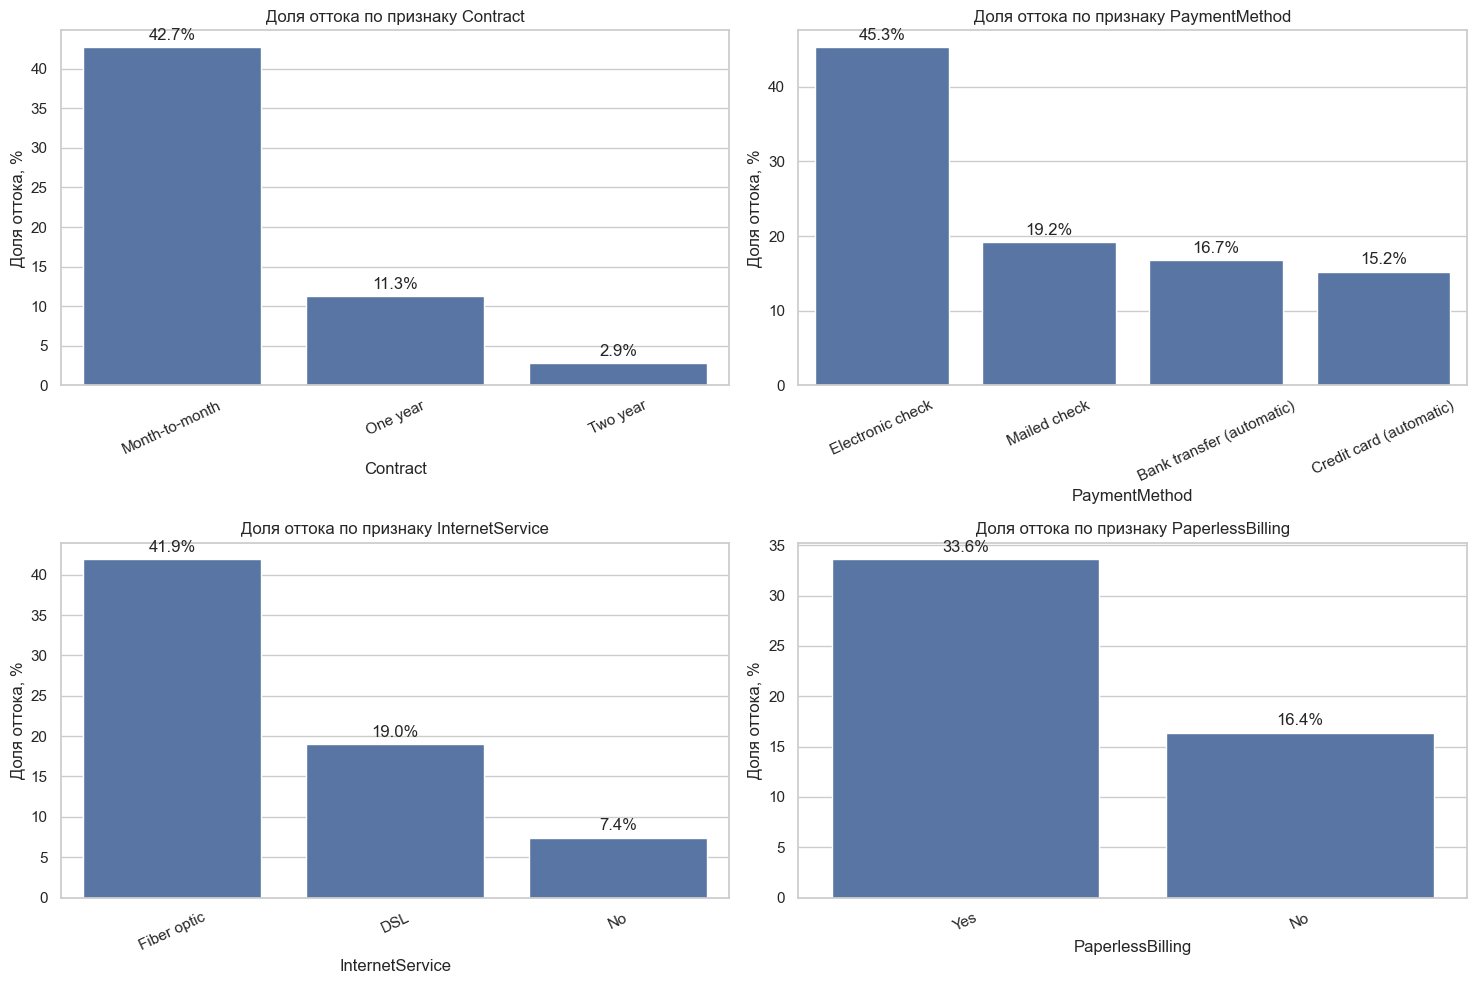

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

for col, ax in zip(cat_cols, axes.flat):
    summary = churn_summary(df, col).sort_values(
        "churn_rate_pct",
        ascending=False
    )

    sns.barplot(
        x=summary.index,
        y=summary["churn_rate_pct"],
        color="#4C72B0",
        ax=ax
    )

    ax.set_title(f"Доля оттока по признаку {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Доля оттока, %")
    ax.tick_params(axis="x", rotation=25)

    for container in ax.containers:
        ax.bar_label(
            container,
            fmt="%.1f%%",
            padding=3
        )

plt.tight_layout()

fig.savefig(
    FIGURES_DIR / "categorical_churn_rates.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

## Анализ оттока по категориальным признакам

**Тип контракта (`Contract`).** Наиболее высокая доля оттока наблюдается среди клиентов с помесячным контрактом. Для долгосрочных контрактов доля оттока существенно ниже. Это одна из основных закономерностей, требующих дальнейшего изучения.

**Способ оплаты (`PaymentMethod`).** У клиентов, использующих Electronic check, наблюдается более высокая доля оттока, чем у клиентов с другими способами оплаты. Необходимо проверить, насколько различаются размеры соответствующих групп и какие дополнительные характеристики связаны с этим различием.

**Тип интернет-подключения (`InternetService`).** На графике видны различия в доле оттока между категориями подключения. Эти различия могут быть связаны с набором услуг, стоимостью обслуживания и другими характеристиками клиентов.

**Безбумажный биллинг (`PaperlessBilling`).** Среди клиентов с включённым безбумажным биллингом наблюдается более высокая доля оттока. Однако этот признак может быть связан с другими характеристиками клиентов и не должен интерпретироваться как причина оттока.

Выводы описывают ассоциации в данных. Они не доказывают причинно-следственные связи.


In [10]:
tenure_bins = [0, 12, 24, 48, 72]
tenure_labels = [
    "0–12 месяцев",
    "13–24 месяца",
    "25–48 месяцев",
    "49–72 месяца"
]

df["tenure_bucket"] = pd.cut(
    df["tenure"],
    bins=tenure_bins,
    labels=tenure_labels,
    include_lowest=True
)

tenure_summary = churn_summary(df, "tenure_bucket")
display(tenure_summary)

segment_summary = (
    df.groupby(
        ["tenure_bucket", "Contract"],
        observed=False
    )["Churn"]
    .agg(
        customers="size",
        churned=lambda s: (s == "Yes").sum()
    )
    .reset_index()
)

segment_summary["churn_rate_pct"] = (
    segment_summary["churned"] /
    segment_summary["customers"] * 100
).round(2)

display(
    segment_summary.sort_values(
        ["tenure_bucket", "Contract"]
    )
)

,customers,churned,churn_rate_pct,share_of_all_churn_pct
tenure_bucket,,,,
0–12 месяцев,2175,1037,47.68,55.48
13–24 месяца,1024,294,28.71,15.73
25–48 месяцев,1594,325,20.39,17.39
49–72 месяца,2239,213,9.51,11.40


,tenure_bucket,Contract,customers,churned,churn_rate_pct
0,0–12 месяцев,Month-to-month,1994,1024,51.35
1,0–12 месяцев,One year,123,13,10.57
2,0–12 месяцев,Two year,58,0,0.00
3,13–24 месяца,Month-to-month,737,278,37.72
4,13–24 месяца,One year,197,16,8.12
5,13–24 месяца,Two year,90,0,0.00
6,25–48 месяцев,Month-to-month,802,264,32.92
7,25–48 месяцев,One year,518,55,10.62
8,25–48 месяцев,Two year,274,6,2.19
9,49–72 месяца,Month-to-month,342,89,26.02


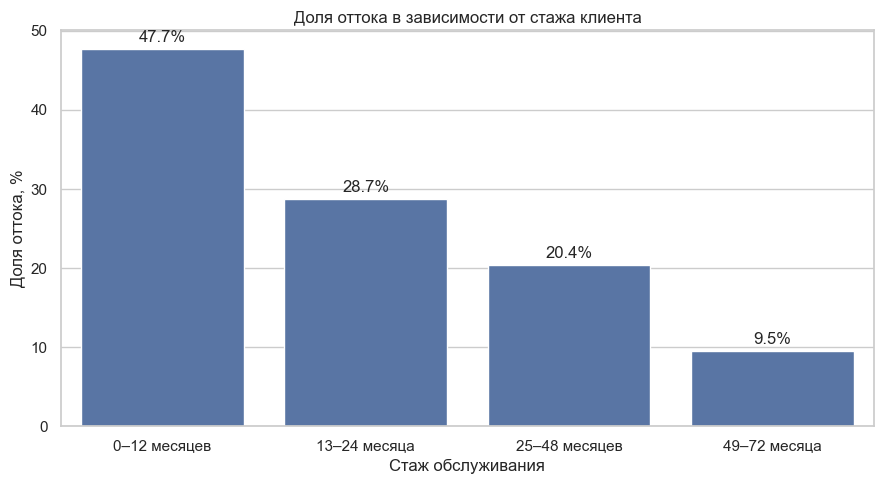

In [11]:
tenure_plot_data = (
    tenure_summary
    .reindex(tenure_labels)
    .reset_index()
)

fig, ax = plt.subplots(figsize=(9, 5))

sns.barplot(
    data=tenure_plot_data,
    x="tenure_bucket",
    y="churn_rate_pct",
    color="#4C72B0",
    ax=ax
)

ax.set_title("Доля оттока в зависимости от стажа клиента")
ax.set_xlabel("Стаж обслуживания")
ax.set_ylabel("Доля оттока, %")

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.1f%%",
        padding=3
    )

plt.tight_layout()

fig.savefig(
    FIGURES_DIR / "churn_by_tenure.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

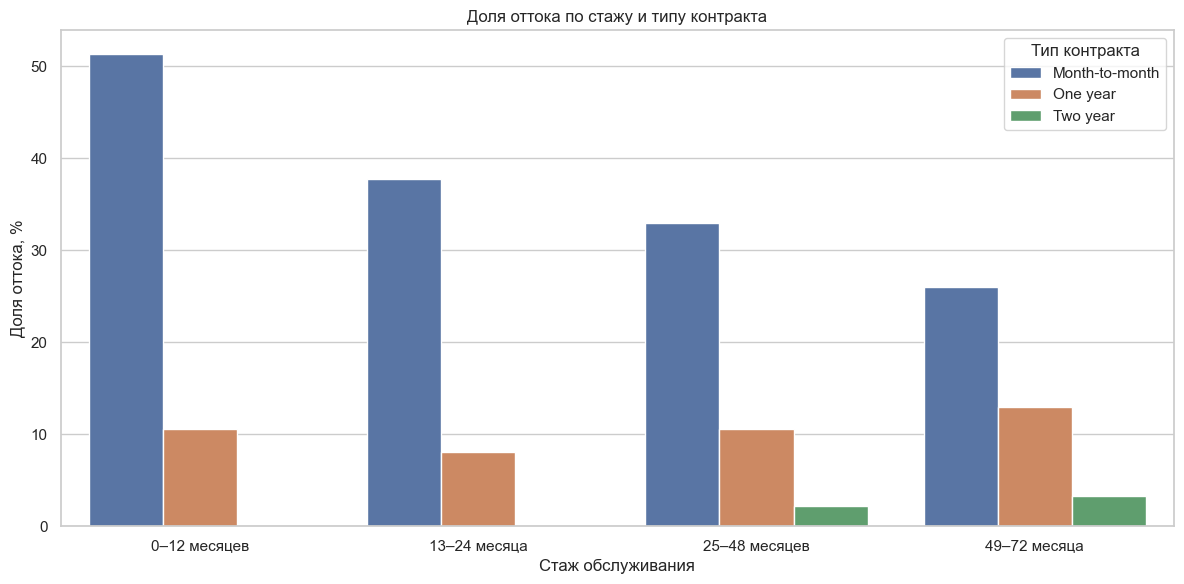

In [12]:
fig, ax = plt.subplots(figsize=(12, 6))

sns.barplot(
    data=segment_summary,
    x="tenure_bucket",
    y="churn_rate_pct",
    hue="Contract",
    order=tenure_labels,
    hue_order=["Month-to-month", "One year", "Two year"],
    ax=ax
)

ax.set_title("Доля оттока по стажу и типу контракта")
ax.set_xlabel("Стаж обслуживания")
ax.set_ylabel("Доля оттока, %")
ax.legend(title="Тип контракта")

plt.tight_layout()

fig.savefig(
    FIGURES_DIR / "churn_by_tenure_and_contract.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

## Интерпретация совместного анализа стажа и контракта
Для более подробного изучения оттока клиенты были разделены
на группы по стажу обслуживания. Внутри каждой группы
сравнивалась доля оттока для разных типов контракта.

**Отток по группам стажа.**

Наибольшая доля оттока наблюдается среди клиентов
со стажем от 0 до 12 месяцев — 47,68%.

По мере увеличения стажа доля оттока снижается:
- 0–12 месяцев — 47,68%;
- 13–24 месяца — 28,71%;
- 25–48 месяцев — 20,39%;
- 49–72 месяца — 9,51%.

**Сравнение типов контракта внутри групп стажа.**

В каждой из четырёх групп стажа наибольшая доля оттока
наблюдается среди клиентов с помесячным контрактом.

Для клиентов с помесячным контрактом показатели составляют:
- 0–12 месяцев — 51,35%;
- 13–24 месяца — 37,72%;
- 25–48 месяцев — 32,92%;
- 49–72 месяца — 26,02%.

Для клиентов с двухлетним контрактом доля оттока
в соответствующих группах составляет 0,00%, 0,00%,
2,19% и 3,33%.

При этом размеры сегментов различаются. Например,
в группе со стажем 0–12 месяцев двухлетний контракт
имеют 58 клиентов, а помесячный — 1 994 клиента.

Поэтому нулевую долю оттока в небольших сегментах
не следует интерпретировать как гарантию отсутствия
оттока у клиентов с таким контрактом.

**Общий вывод.**

Описательный анализ показывает, что внутри каждой группы
стажа клиенты с помесячным контрактом имеют более высокую
долю оттока по сравнению с клиентами с долгосрочными
контрактами.

Также наблюдается снижение доли оттока с увеличением
стажа обслуживания.

Эти результаты позволяют предположить, что стаж
и тип контракта являются важными направлениями
для дальнейшего исследования оттока.

Однако отдельная статистическая проверка различий
между типами контракта внутри каждой группы стажа
в данном анализе не проводилась.

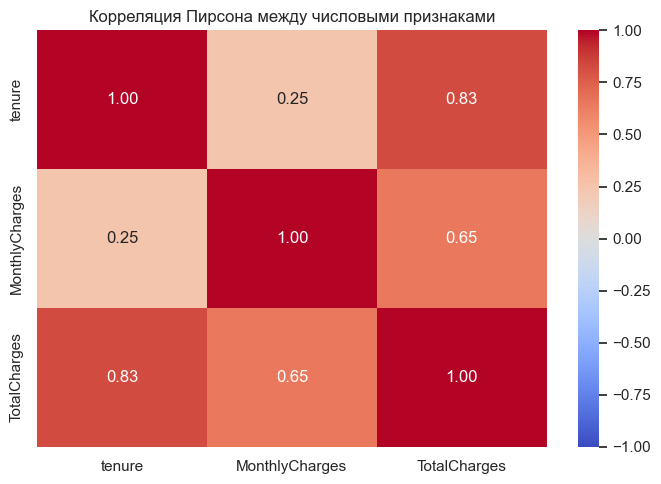

In [13]:
corr_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
corr = df[corr_cols].corr(method="pearson")

plt.figure(figsize=(7, 5))
sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    fmt=".2f"
)
plt.title("Корреляция Пирсона между числовыми признаками")
plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "correlation_heatmap.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

## Интерпретация корреляций

Корреляционная матрица показывает направление и силу линейной связи между числовыми признаками.

Наибольшая корреляция наблюдается между `tenure` и `TotalCharges`. Это закономерно: суммарные платежи зависят от продолжительности обслуживания. Поэтому при дальнейшем моделировании эти признаки могут содержать частично пересекающуюся информацию.

Корреляция между tenure и MonthlyCharges положительная и слабая (r = 0,25). В этой выборке клиенты с большим стажем имеют тенденцию к несколько более высоким ежемесячным платежам.
Между MonthlyCharges и TotalCharges наблюдается положительная корреляция средней силы (r = 0,65).
Наиболее сильная положительная линейная связь — между tenure и TotalCharges (r = 0,83). Это ожидаемо, поскольку суммарные платежи связаны с продолжительностью обслуживания и размером ежемесячной платы.

Корреляция не доказывает причинно-следственную связь и не показывает, насколько хорошо признак предсказывает отток. Для оценки связи с целевой переменной используются отдельные сравнения групп (см. раздел сравнения числовых признаков по факту оттока) и результаты последующего моделирования.

In [14]:
from scipy.stats import mannwhitneyu, chi2_contingency

tenure_no = df.loc[df["Churn"] == "No", "tenure"]
tenure_yes = df.loc[df["Churn"] == "Yes", "tenure"]

u_stat, p_value = mannwhitneyu(
    tenure_no,
    tenure_yes,
    alternative="two-sided"
)

print("Гипотеза 1: распределение tenure различается у ушедших и оставшихся")
print(f"U-statistic: {u_stat:.2f}")
print(f"p-value: {p_value:.6g}")
alpha = 0.05
if p_value < alpha:
    print("Есть статистические основания считать распределения различными.")
else:
    print("Недостаточно оснований отвергнуть нулевую гипотезу.")


contract_table = pd.crosstab(df["Contract"], df["Churn"])

chi2, p_value_contract, dof, expected = chi2_contingency(contract_table)
# размер эффекта: V Крамера

n = contract_table.to_numpy().sum()

min_dimension = min(
    contract_table.shape[0] - 1,
    contract_table.shape[1] - 1
)

cramers_v = np.sqrt(
    chi2 / (n * min_dimension)
)

# размер эффекта для критерия Манна — Уитни
n_no = len(tenure_no)
n_yes = len(tenure_yes)

rank_biserial = (
    2 * u_stat / (n_no * n_yes) - 1
)

print(
    "Rank-biserial correlation:",
    round(rank_biserial, 3)
)
print(f"V Крамера: {cramers_v:.3f}")
print("\nГипотеза 2: тип контракта связан с оттоком")
print("Таблица сопряжённости:")
display(contract_table)
print(f"Chi-square: {chi2:.2f}")
print(f"Degrees of freedom: {dof}")
print(f"p-value: {p_value_contract:.6g}")

if p_value_contract < alpha:
    print("Есть статистические основания считать тип контракта связанным с оттоком.")
else:
    print("Недостаточно оснований отвергнуть нулевую гипотезу.")

Гипотеза 1: распределение tenure различается у ушедших и оставшихся
U-statistic: 7154668.00
p-value: 6.04305e-211
Есть статистические основания считать распределения различными.
Rank-biserial correlation: 0.483
V Крамера: 0.410

Гипотеза 2: тип контракта связан с оттоком
Таблица сопряжённости:


Churn,No,Yes
Contract,,
Month-to-month,2220,1655
One year,1306,166
Two year,1637,48


Chi-square: 1179.55
Degrees of freedom: 2
p-value: 7.32618e-257
Есть статистические основания считать тип контракта связанным с оттоком.


## Ограничения статистического анализа

В работе использованы два статистических критерия.

**1. Критерий Манна — Уитни.**

Использован для сравнения распределения стажа обслуживания
(`tenure`) между ушедшими и оставшимися клиентами.

Полученное p-value составляет 6,04e-211.
При уровне значимости 0,05 имеются статистические
основания отвергнуть нулевую гипотезу об отсутствии
различий между распределениями.

**2. Критерий хи-квадрат.**

Использован для проверки связи между типом контракта
(`Contract`) и фактом оттока (`Churn`).

Полученное p-value составляет 7,33e-257.
При уровне значимости 0,05 имеются статистические
основания отвергнуть нулевую гипотезу об отсутствии
связи между этими категориальными признаками.

**Ограничения интерпретации.**

- Статистическая значимость не доказывает причинно-следственную связь.
- Маленькое p-value не означает, что различие обязательно
  велико или имеет существенное практическое значение.
- Критерий Манна — Уитни сравнивает распределения двух групп,
  а не проверяет непосредственно различие средних значений.
- Проведённые тесты не учитывают одновременно все
  характеристики клиентов.
- Статистическая связь между контрактом и оттоком
  не доказывает, что изменение типа контракта само по себе
  приведёт к снижению оттока.
- Различия в доле оттока внутри отдельных групп стажа
  описаны, но отдельно статистически не проверялись.

Таким образом, результаты тестов подтверждают наличие
статистических различий и связи в исследуемой выборке,
но для оценки прогностической ценности признаков
необходимо построить и проверить модель на отложенных данных.

# Итоговые выводы EDA

## 1. Общая информация о данных

В исследовании использована таблица клиентов
телеком-компании, содержащая 7 032 записи и 21 столбец.

Целевая переменная — `Churn`, отражающая факт
прекращения обслуживания клиентом.

В выборке 1 869 ушедших клиентов, что составляет 26,58%.
Оставшиеся 5 163 клиента составляют 73,42%.

Таким образом, классы распределены неравномерно.
При построении модели необходимо учитывать это
и оценивать качество не только по accuracy,
но и по precision, recall, F1-score и ROC-AUC.

## 2. Качество данных

На этапе первичной проверки:

- пропущенные значения не обнаружены;
- полные дубликаты строк отсутствуют;
- повторяющиеся значения `customerID` отсутствуют;
- все идентификаторы клиентов уникальны.

Данные не потребовали обработки пропусков
или удаления полных дубликатов на этапе EDA.

## 3. Основные закономерности

**Тип контракта (`Contract`).**

Наибольшая доля оттока наблюдается среди клиентов
с помесячным контрактом — 42,71%.

Для клиентов с годовым контрактом показатель составляет
11,28%, а для клиентов с двухлетним контрактом — 2,85%.

Это наиболее заметное различие среди рассмотренных
категориальных признаков.

**Стаж обслуживания (`tenure`).**

Медианный стаж ушедших клиентов составляет 10 месяцев,
тогда как у оставшихся клиентов — 38 месяцев.

При сегментации по стажу также наблюдается снижение
доли оттока с увеличением продолжительности обслуживания:

- 0–12 месяцев — 47,68%;
- 13–24 месяца — 28,71%;
- 25–48 месяцев — 20,39%;
- 49–72 месяца — 9,51%.

Это указывает на то, что клиенты с небольшим стажем
представляют важный сегмент для дальнейшего исследования.

**Способ оплаты (`PaymentMethod`).**

Наибольшая доля оттока наблюдается среди клиентов,
использующих Electronic check, — 45,29%.

На эту категорию приходится 57,30% всех ушедших клиентов.

Данный признак заслуживает дальнейшего изучения
при построении модели прогнозирования.

**Тип интернет-подключения (`InternetService`).**

Среди клиентов с Fiber optic доля оттока составляет 41,89%.
Для DSL показатель равен 19,00%, а среди клиентов
без интернет-подключения — 7,43%.

Различия могут быть связаны с другими характеристиками
клиентов и набором подключённых услуг.

**Безбумажный биллинг (`PaperlessBilling`).**

Среди клиентов с включённым PaperlessBilling доля
оттока составляет 33,59%, а среди клиентов без него —
16,38%.

Это наблюдаемая связь, которая требует дополнительного
изучения с учётом других характеристик клиентов.

**Ежемесячная плата (`MonthlyCharges`).**

Медиана ежемесячной платы у ушедших клиентов составляет
79,65, у оставшихся — 64,45.

Таким образом, в исследуемой выборке ушедшие клиенты
имеют более высокую медианную ежемесячную плату.

Однако это различие не доказывает, что высокая стоимость
услуг является причиной оттока.

**Суммарные платежи (`TotalCharges`).**

Медиана суммарных платежей у ушедших клиентов составляет
703,55, у оставшихся — 1 683,60.

Более низкие суммарные платежи у ушедших клиентов
могут объясняться меньшим стажем обслуживания.

Поэтому данный признак необходимо анализировать
совместно с продолжительностью обслуживания.

## 4. Совместный анализ стажа и контракта

В каждой из четырёх групп стажа доля оттока среди клиентов
с помесячным контрактом выше, чем среди клиентов
с годовыми и двухлетними контрактами.

Например, среди клиентов со стажем 0–12 месяцев
доля оттока для помесячного контракта составляет 51,35%,
а для годового — 10,57%.

Это описательное наблюдение показывает, что различия
между типами контракта заметны и при сравнении клиентов
с сопоставимым стажем.

При этом статистическая проверка различий внутри
каждой группы стажа отдельно не проводилась.

## 5. Корреляционный анализ

Наиболее сильная положительная корреляция наблюдается
между `tenure` и `TotalCharges` (r = 0,83).

Между `MonthlyCharges` и `TotalCharges` корреляция
составляет 0,65.

Связь между `tenure` и `MonthlyCharges` слабая
и положительная (r = 0,25).

При дальнейшем моделировании следует учитывать,
что `tenure` и `TotalCharges` содержат частично
пересекающуюся информацию.

Корреляция не доказывает причинно-следственную связь
и не является самостоятельной оценкой прогностической
значимости признаков.

## 6. Результаты статистических тестов

**Критерий Манна — Уитни.**

Для сравнения распределения стажа у ушедших
и оставшихся клиентов получено p-value = 6,04e-211.

При уровне значимости 0,05 имеются статистические
основания считать распределения стажа различающимися.

**Критерий хи-квадрат.**

Для проверки связи типа контракта с оттоком получено
p-value = 7,33e-257.

При уровне значимости 0,05 имеются статистические
основания считать тип контракта связанным с оттоком.

Полученные результаты показывают статистическую
значимость различий и связи, но не доказывают
причинно-следственные отношения.

## 7. Практическая интерпретация

По результатам EDA можно выделить несколько сегментов,
которые заслуживают особого внимания при дальнейшем
изучении оттока:

- клиенты с небольшим стажем обслуживания;
- клиенты с помесячным контрактом;
- клиенты, использующие Electronic check;
- клиенты с подключением Fiber optic.

Эти сегменты характеризуются сравнительно высокой
долей оттока в исследуемой выборке.

Результаты могут использоваться для формирования
гипотез о факторах, связанных с прекращением обслуживания.

При этом нельзя утверждать, что изменение одного
из перечисленных признаков само по себе приведёт
к снижению оттока.

## 8. Ограничения исследования

- Данные относятся к одной телеком-компании и не обязательно
  отражают закономерности других компаний и рынков.
- EDA выявляет ассоциации, но не доказывает причинность.
- Статистические тесты проверяют отдельные связи
  и не учитывают одновременно все характеристики клиентов.
- Некоторые сегменты имеют небольшой размер выборки,
  поэтому их результаты требуют осторожной интерпретации.
- До построения и проверки модели нельзя утверждать,
  какие признаки являются наиболее важными
  для прогнозирования оттока.
- Данные отражают конкретный период наблюдения,
  поэтому результаты не обязательно сохранятся
  в будущих периодах.

## 9. Следующие шаги

На следующем этапе планируется:

1. Подготовить признаки для моделирования.
2. Разделить данные на обучающую и тестовую выборки
   с сохранением доли классов.
3. Построить baseline-модель DummyClassifier.
4. Обучить LogisticRegression.
5. Сравнить модели по precision, recall, F1-score,
   ROC-AUC и PR-AUC.
6. Проанализировать матрицу ошибок и ошибки классификации.
7. Проверить, какие признаки помогают прогнозировать
   отток на данных, не использованных при обучении.

Результаты EDA используются для формирования гипотез
и подготовки к моделированию. Качество прогнозирования
будет оцениваться отдельно на отложенной выборке.